# Personalized Learning Recommendation System

## Project Overview

This project aims to develop a Personalized Learning Recommendation System using student learning data.

The system analyses student information and learning patterns to identify suitable courses and learning resources.

## Project Workflow

Dataset
→ Data Understanding
→ Data Cleaning
→ Exploratory Data Analysis
→ Feature Engineering
→ Machine Learning
→ Personalized Recommendations
→ Evaluation

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Load Student Dataset

In this step, we load the LMS Student Dataset from the Excel file and inspect its available sheets.

In [4]:
import pandas as pd
import os

DATA_PATH = "../dataset/raw/lms/LMS Student Data Set.xlsx"

if os.path.exists(DATA_PATH):

    print("Dataset found successfully!")

    excel_file = pd.ExcelFile(DATA_PATH)

    print("\nAvailable Sheets:")
    print(excel_file.sheet_names)

else:
    print("Dataset file not found. Check the file path.")

Dataset found successfully!

Available Sheets:
['Student data set']


In [5]:
for sheet in excel_file.sheet_names:

    df = pd.read_excel(DATA_PATH, sheet_name=sheet)

    print("\n" + "=" * 60)
    print("SHEET:", sheet)
    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 5 Records:")
    display(df.head())


SHEET: Student data set
Shape: (200, 21)

Columns:
['S.No.', 'Student-Id', 'Gender', 'Region', 'Age_band', 'Code Module', 'Label', 'Average Course \nFeedback', 'Code Presentation\n(Start of the course with year & month)\nJ-June \nD-December', 'Duration\n(In weeks)', 'Studied credits', 'No.of previous attempts', 'Assessment ID', 'Assessment type', 'Date_registered', 'Course duration start date', 'Date of submission', 'No.of days viewed', 'Total clicks', 'No.of clicks person done', 'No.of exercises']

First 5 Records:


,S.No.,Student-Id,Gender,Region,Age_band,Code Module,Label,Average Course \nFeedback,Code Presentation\n(Start of the course with year & month)\nJ-June \nD-December,Duration\n(In weeks),...,No.of previous attempts,Assessment ID,Assessment type,Date_registered,Course duration start date,Date of submission,No.of days viewed,Total clicks,No.of clicks person done,No.of exercises
0,1,201801057,M,MADURAI,19,CS8391,2,3.37,2018J,2,...,0,IAT1(Internal Assessment Test1),QUIZ,2019-05-06 00:00:00,2019-10-06,24-06-2019,4,5.0,4.0,10.0
1,2,201801058,F,CHENNAI,19,CS8392,3,4.01,2018D,3,...,1,IAT1,ASSIGNMENT,27-11-2019,2019-04-12,25-12-2019,6,5.0,5.0,3.0
2,3,201801059,M,CHENNAI,20,CS8391,2,3.37,2018J,2,...,1,IAT1,QUIZ,2019-05-06 00:00:00,2019-10-06,24-06-2019,8,5.0,4.0,10.0
3,4,201801060,M,CHENNAI,19,CS8392,3,4.01,2018D,3,...,0,IAT1,ASSIGNMENT,27-11-2019,2019-04-12,25-12-2019,5,5.0,5.0,3.0
4,5,201801061,M,CHENNAI,19,CS8391,2,3.37,2018J,2,...,0,IAT1,QUIZ,2019-05-06 00:00:00,2019-10-06,24-06-2019,5,5.0,4.0,10.0


## 2. Dataset Structure and Data Quality

In this section, we inspect the dataset columns, data types, missing values, unique values and target label distribution.

This helps us identify the useful student features and determine the recommendation strategy.

In [6]:
# Load the first sheet
df = pd.read_excel(
    DATA_PATH,
    sheet_name=excel_file.sheet_names[0]
)

# Complete column names
print("Total Columns:", len(df.columns))
print("\nColumn Names:")
for i, col in enumerate(df.columns, 1):
    print(i, ":", col)

# Dataset shape
print("\nDataset Shape:", df.shape)

# Data types
print("\nData Types:")
display(df.dtypes)

# Missing values
print("\nMissing Values:")
display(df.isnull().sum())

# Label distribution
if "Label" in df.columns:
    print("\nLabel Distribution:")
    display(df["Label"].value_counts(dropna=False))

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

Total Columns: 21

Column Names:
1 : S.No.
2 : Student-Id
3 : Gender
4 : Region
5 : Age_band
6 : Code Module
7 : Label
8 : Average Course 
Feedback
9 : Code Presentation
(Start of the course with year & month)
J-June 
D-December
10 : Duration
(In weeks)
11 : Studied credits
12 : No.of previous attempts
13 : Assessment ID
14 : Assessment type
15 : Date_registered
16 : Course duration start date
17 : Date of submission
18 : No.of days viewed
19 : Total clicks
20 : No.of clicks person done
21 : No.of exercises

Dataset Shape: (200, 21)

Data Types:


S.No.                                                                                       int64
Student-Id                                                                                  int64
Gender                                                                                        str
Region                                                                                        str
Age_band                                                                                    int64
Code Module                                                                                   str
Label                                                                                       int64
Average Course \nFeedback                                                                 float64
Code Presentation\n(Start of the course with year & month)\nJ-June \nD-December               str
Duration\n(In weeks)                                                                        int64
Studied credits     


Missing Values:


S.No.                                                                                0
Student-Id                                                                           0
Gender                                                                               0
Region                                                                               0
Age_band                                                                             0
Code Module                                                                          0
Label                                                                                0
Average Course \nFeedback                                                            0
Code Presentation\n(Start of the course with year & month)\nJ-June \nD-December      0
Duration\n(In weeks)                                                                 0
Studied credits                                                                      0
No.of previous attempts                    


Label Distribution:


Label
2    71
1    69
3    60
Name: count, dtype: int64


Duplicate Rows: 0


In [7]:
# Clean column names for easier handling
df.columns = (
    df.columns
    .str.replace("\n", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("DATASET SUMMARY")
print("-" * 45)

print("Total Records:", len(df))
print("Total Students:", df["Student-Id"].nunique())
print("Unique Courses:", df["Code Module"].nunique())
print("Unique Regions:", df["Region"].nunique())

print("\nLABEL DISTRIBUTION")
display(df["Label"].value_counts(dropna=False))

print("\nMISSING VALUES")
missing = df.isnull().sum()
display(missing[missing > 0])

print("\nDUPLICATE ROWS:", df.duplicated().sum())

print("\nRECORDS PER STUDENT")
display(df["Student-Id"].value_counts().describe())

DATASET SUMMARY
---------------------------------------------
Total Records: 200
Total Students: 164
Unique Courses: 5
Unique Regions: 2

LABEL DISTRIBUTION


Label
2    71
1    69
3    60
Name: count, dtype: int64


MISSING VALUES


Total clicks                145
No.of clicks person done    146
No.of exercises             147
dtype: int64


DUPLICATE ROWS: 0

RECORDS PER STUDENT


count    164.000000
mean       1.219512
std        0.415184
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        2.000000
Name: count, dtype: float64

In [8]:
print("STUDENT COURSE MAPPING")

student_course = (
    df.groupby("Student-Id")
    .agg(
        total_records=("Code Module", "count"),
        unique_courses=("Code Module", "nunique")
    )
    .reset_index()
)

display(student_course.head(10))

print("\nCOURSE DISTRIBUTION")
display(df["Code Module"].value_counts())

print("\nASSESSMENT TYPE DISTRIBUTION")
display(df["Assessment type"].value_counts())

STUDENT COURSE MAPPING


,Student-Id,total_records,unique_courses
0,201801001,2,2
1,201801002,1,1
2,201801003,2,2
3,201801004,2,2
4,201801005,2,2
5,201801006,1,1
6,201801007,1,1
7,201801008,1,1
8,201801009,1,1
9,201801010,1,1



COURSE DISTRIBUTION


Code Module
CS8392    47
EC8395    45
MA8351    43
CS8391    34
CS8351    31
Name: count, dtype: int64


ASSESSMENT TYPE DISTRIBUTION


Assessment type
QUIZ          103
ASSIGNMENT     97
Name: count, dtype: int64

In [9]:
print("LABEL-WISE STUDENT DETAILS")

display(
    df.groupby("Label").agg(
        total_records=("Student-Id", "count"),
        unique_students=("Student-Id", "nunique"),
        avg_clicks=("Total clicks", "mean"),
        avg_exercises=("No.of exercises", "mean"),
        avg_days_viewed=("No.of days viewed", "mean"),
        avg_previous_attempts=("No.of previous attempts", "mean")
    )
)

LABEL-WISE STUDENT DETAILS


,total_records,unique_students,avg_clicks,avg_exercises,avg_days_viewed,avg_previous_attempts
Label,,,,,,
1,69,62,7.473684,7.705882,12.304348,0.536232
2,71,66,6.760000,7.880000,12.309859,0.422535
3,60,56,6.363636,7.090909,12.266667,0.466667


In [10]:
# Label vs course relationship
print("LABEL VS COURSE")

display(
    pd.crosstab(
        df["Code Module"],
        df["Label"]
    )
)

# Student course examples
print("\nSTUDENT COURSE DETAILS")

display(
    df[
        [
            "Student-Id",
            "Code Module",
            "Label",
            "Average Course Feedback",
            "No.of previous attempts",
            "Assessment type"
        ]
    ].head(15)
)

# Check repeated students
print("\nSTUDENTS WITH MULTIPLE RECORDS")

display(
    student_course[
        student_course["total_records"] > 1
    ]
)

LABEL VS COURSE


Label,1,2,3
Code Module,,,
CS8351,11,12,8
CS8391,10,15,9
CS8392,21,22,4
EC8395,17,11,17
MA8351,10,11,22



STUDENT COURSE DETAILS


,Student-Id,Code Module,Label,Average Course Feedback,No.of previous attempts,Assessment type
0,201801057,CS8391,2,3.37,0,QUIZ
1,201801058,CS8392,3,4.01,1,ASSIGNMENT
2,201801059,CS8391,2,3.37,1,QUIZ
3,201801060,CS8392,3,4.01,0,ASSIGNMENT
4,201801061,CS8391,2,3.37,0,QUIZ
5,201801062,CS8391,1,3.37,1,QUIZ
6,201801063,CS8391,2,3.37,0,QUIZ
7,201801064,CS8391,3,3.37,0,QUIZ
8,201801065,CS8392,2,4.01,0,ASSIGNMENT
9,201801066,CS8391,3,3.37,1,QUIZ



STUDENTS WITH MULTIPLE RECORDS


,Student-Id,total_records,unique_courses
0,201801001,2,2
2,201801003,2,2
3,201801004,2,2
4,201801005,2,2
10,201801011,2,2
18,201801019,2,2
21,201801022,2,2
24,201801025,2,2
30,201801031,2,2
40,201801042,2,2


In [11]:
print("LABEL-WISE ACADEMIC PROFILE")

display(
    df.groupby("Label").agg(
        students=("Student-Id", "nunique"),
        avg_feedback=("Average Course Feedback", "mean"),
        avg_attempts=("No.of previous attempts", "mean"),
        avg_clicks=("Total clicks", "mean"),
        avg_days_viewed=("No.of days viewed", "mean"),
        avg_exercises=("No.of exercises", "mean")
    ).round(2)
)

LABEL-WISE ACADEMIC PROFILE


,students,avg_feedback,avg_attempts,avg_clicks,avg_days_viewed,avg_exercises
Label,,,,,,
1,62,3.34,0.54,7.47,12.30,7.71
2,66,3.38,0.42,6.76,12.31,7.88
3,56,2.97,0.47,6.36,12.27,7.09


In [12]:
# Student-level learning profile

student_profile = (
    df.groupby("Student-Id")
    .agg(
        courses_enrolled=("Code Module", "nunique"),
        avg_feedback=("Average Course Feedback", "mean"),
        previous_attempts=("No.of previous attempts", "sum"),
        days_viewed=("No.of days viewed", "sum"),
        total_clicks=("Total clicks", "sum"),
        total_exercises=("No.of exercises", "sum")
    )
    .reset_index()
)

display(student_profile.head(10))

print("Unique student profiles:", len(student_profile))

,Student-Id,courses_enrolled,avg_feedback,previous_attempts,days_viewed,total_clicks,total_exercises
0,201801001,2,2.92,1,27,0.0,0.0
1,201801002,1,4.01,0,16,0.0,0.0
2,201801003,2,2.92,1,33,0.0,0.0
3,201801004,2,3.69,1,27,20.0,7.0
4,201801005,2,3.44,1,26,8.0,8.0
5,201801006,1,3.51,0,14,0.0,0.0
6,201801007,1,2.91,1,7,0.0,0.0
7,201801008,1,2.91,1,8,0.0,0.0
8,201801009,1,2.47,1,10,0.0,0.0
9,201801010,1,4.01,0,6,0.0,0.0


Unique student profiles: 164


## 3. Data Quality and Missing Value Analysis

In this section, we inspect missing values in student engagement features.

This is important because missing interaction data should not automatically be interpreted as zero learning activity.

In [13]:
engagement_columns = [
    "Total clicks",
    "No.of clicks person done",
    "No.of exercises"
]

print("Missing values:")
display(df[engagement_columns].isnull().sum())

print("\nZero values:")
display((df[engagement_columns] == 0).sum())

print("\nNon-null values:")
display(df[engagement_columns].count())

Missing values:


Total clicks                145
No.of clicks person done    146
No.of exercises             147
dtype: int64


Zero values:


Total clicks                0
No.of clicks person done    0
No.of exercises             0
dtype: int64


Non-null values:


Total clicks                55
No.of clicks person done    54
No.of exercises             53
dtype: int64

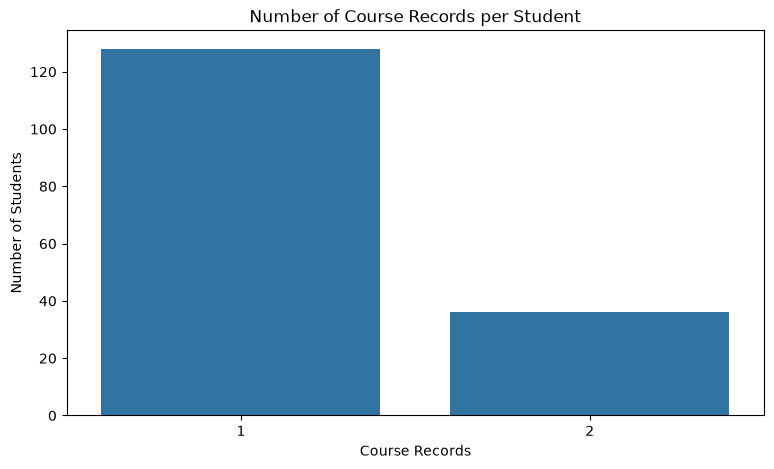

In [14]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=student_course,
    x="total_records"
)

plt.title("Number of Course Records per Student")
plt.xlabel("Course Records")
plt.ylabel("Number of Students")

plt.show()

In [15]:
student_profile = (
    df.groupby("Student-Id")
    .agg(
        courses_enrolled=("Code Module", "nunique"),
        avg_feedback=("Average Course Feedback", "mean"),
        previous_attempts=("No.of previous attempts", "sum"),
        days_viewed=("No.of days viewed", "sum"),
        total_clicks=("Total clicks", lambda x: x.sum(min_count=1)),
        total_exercises=("No.of exercises", lambda x: x.sum(min_count=1)),
        available_click_records=("Total clicks", "count"),
        available_exercise_records=("No.of exercises", "count")
    )
    .reset_index()
)

print("Total Student Profiles:", len(student_profile))
display(student_profile.head(10))

Total Student Profiles: 164


,Student-Id,courses_enrolled,avg_feedback,previous_attempts,days_viewed,total_clicks,total_exercises,available_click_records,available_exercise_records
0,201801001,2,2.92,1,27,NaN,NaN,0,0
1,201801002,1,4.01,0,16,NaN,NaN,0,0
2,201801003,2,2.92,1,33,NaN,NaN,0,0
3,201801004,2,3.69,1,27,20.0,7.0,2,1
4,201801005,2,3.44,1,26,8.0,8.0,1,1
5,201801006,1,3.51,0,14,NaN,NaN,0,0
6,201801007,1,2.91,1,7,NaN,NaN,0,0
7,201801008,1,2.91,1,8,NaN,NaN,0,0
8,201801009,1,2.47,1,10,NaN,NaN,0,0
9,201801010,1,4.01,0,6,NaN,NaN,0,0


In [16]:
print("Student Profile Missing Values:")
display(student_profile.isnull().sum())

print("\nCourse Enrollment Distribution:")
display(student_profile["courses_enrolled"].value_counts().sort_index())

Student Profile Missing Values:


Student-Id                      0
courses_enrolled                0
avg_feedback                    0
previous_attempts               0
days_viewed                     0
total_clicks                  113
total_exercises               114
available_click_records         0
available_exercise_records      0
dtype: int64


Course Enrollment Distribution:


courses_enrolled
1    128
2     36
Name: count, dtype: int64

In [17]:
profile_columns = [
    "courses_enrolled",
    "avg_feedback",
    "previous_attempts",
    "days_viewed"
]

print("STUDENT LEARNING PROFILE SUMMARY")
display(student_profile[profile_columns].describe().round(2))

print("\nCOURSE-WISE STUDENT DISTRIBUTION")
display(
    df.groupby("Code Module")
    .agg(
        total_records=("Student-Id", "count"),
        unique_students=("Student-Id", "nunique"),
        avg_feedback=("Average Course Feedback", "mean"),
        avg_attempts=("No.of previous attempts", "mean"),
        avg_days_viewed=("No.of days viewed", "mean")
    )
    .round(2)
)

STUDENT LEARNING PROFILE SUMMARY


,courses_enrolled,avg_feedback,previous_attempts,days_viewed
count,164.00,164.00,164.00,164.00
mean,1.22,3.25,0.58,14.99
std,0.42,0.52,0.59,7.03
min,1.00,2.47,0.00,4.00
25%,1.00,2.91,0.00,10.00
50%,1.00,3.37,1.00,15.00
75%,1.00,3.51,1.00,18.25
max,2.00,4.01,2.00,36.00



COURSE-WISE STUDENT DISTRIBUTION


,total_records,unique_students,avg_feedback,avg_attempts,avg_days_viewed
Code Module,,,,,
CS8351,31,31,3.51,0.74,13.32
CS8391,34,34,3.37,0.32,10.53
CS8392,47,47,4.01,0.21,11.70
EC8395,45,45,2.91,0.84,12.33
MA8351,43,43,2.47,0.30,13.56


In [18]:
print("1. COURSE-WISE LABEL DISTRIBUTION")
display(pd.crosstab(df["Code Module"], df["Label"], margins=True))

print("\n2. ASSESSMENT TYPES")
display(df["Assessment type"].value_counts(dropna=False))

print("\n3. FEEDBACK VALUE DISTRIBUTION")
display(df["Average Course Feedback"].describe())

print("\n4. LABEL VALUES")
display(sorted(df["Label"].dropna().unique().tolist()))

print("\n5. COURSE PRESENTATION VALUES")
display(df["Code Presentation (Start of the course with year & month) J-June D-December"].value_counts(dropna=False))

1. COURSE-WISE LABEL DISTRIBUTION


Label,1,2,3,All
Code Module,,,,
CS8351,11,12,8,31
CS8391,10,15,9,34
CS8392,21,22,4,47
EC8395,17,11,17,45
MA8351,10,11,22,43
All,69,71,60,200



2. ASSESSMENT TYPES


Assessment type
QUIZ          103
ASSIGNMENT     97
Name: count, dtype: int64


3. FEEDBACK VALUE DISTRIBUTION


count    200.000000
mean       3.245100
std        0.554066
min        2.470000
25%        2.910000
50%        3.370000
75%        3.510000
max        4.010000
Name: Average Course Feedback, dtype: float64


4. LABEL VALUES


[1, 2, 3]


5. COURSE PRESENTATION VALUES


Code Presentation (Start of the course with year & month) J-June D-December
2018J    181
2018D     19
Name: count, dtype: int64

In [19]:
course_mapping = {
    "CS8351": "Digital Principles and System Design",
    "CS8391": "Data Structures",
    "CS8392": "Object Oriented Programming",
    "EC8395": "Communication Engineering",
    "MA8351": "Discrete Mathematics"
}

df["Course Name"] = df["Code Module"].map(course_mapping)

display(
    df[["Student-Id", "Code Module", "Course Name"]]
    .drop_duplicates()
    .head(15)
)

,Student-Id,Code Module,Course Name
0,201801057,CS8391,Data Structures
1,201801058,CS8392,Object Oriented Programming
2,201801059,CS8391,Data Structures
3,201801060,CS8392,Object Oriented Programming
4,201801061,CS8391,Data Structures
5,201801062,CS8391,Data Structures
6,201801063,CS8391,Data Structures
7,201801064,CS8391,Data Structures
8,201801065,CS8392,Object Oriented Programming
9,201801066,CS8391,Data Structures


In [20]:
resources = pd.DataFrame([
    # Data Structures
    ["R001", "CS8391", "Data Structures", "Arrays and Linked Lists", "Notes", "Beginner"],
    ["R002", "CS8391", "Data Structures", "Stack and Queue", "Video", "Beginner"],
    ["R003", "CS8391", "Data Structures", "Trees and Graphs", "Practice", "Intermediate"],
    ["R004", "CS8391", "Data Structures", "Sorting and Searching", "Practice", "Intermediate"],

    # Object Oriented Programming
    ["R005", "CS8392", "Object Oriented Programming", "Classes and Objects", "Notes", "Beginner"],
    ["R006", "CS8392", "Object Oriented Programming", "Inheritance and Polymorphism", "Video", "Intermediate"],
    ["R007", "CS8392", "Object Oriented Programming", "Abstraction and Encapsulation", "Notes", "Intermediate"],
    ["R008", "CS8392", "Object Oriented Programming", "OOP Coding Exercises", "Practice", "Beginner"],

    # Digital Principles
    ["R009", "CS8351", "Digital Principles and System Design", "Number Systems and Boolean Algebra", "Notes", "Beginner"],
    ["R010", "CS8351", "Digital Principles and System Design", "Logic Gates", "Video", "Beginner"],
    ["R011", "CS8351", "Digital Principles and System Design", "Combinational Circuits", "Practice", "Intermediate"],

    # Communication Engineering
    ["R012", "EC8395", "Communication Engineering", "Analog Communication Basics", "Notes", "Beginner"],
    ["R013", "EC8395", "Communication Engineering", "Amplitude and Frequency Modulation", "Video", "Intermediate"],
    ["R014", "EC8395", "Communication Engineering", "Communication Systems Practice", "Practice", "Intermediate"],

    # Discrete Mathematics
    ["R015", "MA8351", "Discrete Mathematics", "Logic and Propositions", "Notes", "Beginner"],
    ["R016", "MA8351", "Discrete Mathematics", "Relations and Functions", "Video", "Beginner"],
    ["R017", "MA8351", "Discrete Mathematics", "Graph Theory", "Practice", "Intermediate"]
], columns=[
    "Resource ID", "Course Code", "Course Name",
    "Topic", "Resource Type", "Difficulty"
])

print("Total Learning Resources:", len(resources))
display(resources.head(10))

Total Learning Resources: 17


,Resource ID,Course Code,Course Name,Topic,Resource Type,Difficulty
0,R001,CS8391,Data Structures,Arrays and Linked Lists,Notes,Beginner
1,R002,CS8391,Data Structures,Stack and Queue,Video,Beginner
2,R003,CS8391,Data Structures,Trees and Graphs,Practice,Intermediate
3,R004,CS8391,Data Structures,Sorting and Searching,Practice,Intermediate
4,R005,CS8392,Object Oriented Programming,Classes and Objects,Notes,Beginner
5,R006,CS8392,Object Oriented Programming,Inheritance and Polymorphism,Video,Intermediate
6,R007,CS8392,Object Oriented Programming,Abstraction and Encapsulation,Notes,Intermediate
7,R008,CS8392,Object Oriented Programming,OOP Coding Exercises,Practice,Beginner
8,R009,CS8351,Digital Principles and System Design,Number Systems and Boolean Algebra,Notes,Beginner
9,R010,CS8351,Digital Principles and System Design,Logic Gates,Video,Beginner


In [21]:
# Select a student who has multiple course records
student_id = (
    student_profile
    .sort_values("courses_enrolled", ascending=False)
    .iloc[0]["Student-Id"]
)

selected_student = student_profile[
    student_profile["Student-Id"] == student_id
]

enrolled_courses = df[
    df["Student-Id"] == student_id
][["Code Module", "Course Name"]].drop_duplicates()

print("Selected Student ID:", student_id)

print("\nSTUDENT PROFILE")
display(selected_student)

print("\nENROLLED COURSES")
display(enrolled_courses)

Selected Student ID: 201801001.0

STUDENT PROFILE


,Student-Id,courses_enrolled,avg_feedback,previous_attempts,days_viewed,total_clicks,total_exercises,available_click_records,available_exercise_records
0,201801001,2,2.92,1,27,NaN,NaN,0,0



ENROLLED COURSES


,Code Module,Course Name
61,CS8391,Data Structures
171,MA8351,Discrete Mathematics


In [22]:
# Convert student ID to integer
student_id = int(student_id)

# Get already enrolled course codes
enrolled_codes = set(
    df.loc[df["Student-Id"] == student_id, "Code Module"]
)

# Find courses not yet enrolled in
recommended_resources = resources[
    ~resources["Course Code"].isin(enrolled_codes)
].copy()

# Add recommendation reason
recommended_resources["Recommendation Reason"] = (
    "This course is not present in the student's recorded enrollment history."
)

print("STUDENT ID:", student_id)
print("ALREADY ENROLLED:", list(enrolled_codes))
print("\nRECOMMENDED LEARNING RESOURCES:")

display(
    recommended_resources[
        [
            "Resource ID",
            "Course Name",
            "Topic",
            "Resource Type",
            "Difficulty",
            "Recommendation Reason"
        ]
    ]
)

STUDENT ID: 201801001
ALREADY ENROLLED: ['MA8351', 'CS8391']

RECOMMENDED LEARNING RESOURCES:


,Resource ID,Course Name,Topic,Resource Type,Difficulty,Recommendation Reason
4,R005,Object Oriented Programming,Classes and Objects,Notes,Beginner,This course is not present in the student's re...
5,R006,Object Oriented Programming,Inheritance and Polymorphism,Video,Intermediate,This course is not present in the student's re...
6,R007,Object Oriented Programming,Abstraction and Encapsulation,Notes,Intermediate,This course is not present in the student's re...
7,R008,Object Oriented Programming,OOP Coding Exercises,Practice,Beginner,This course is not present in the student's re...
8,R009,Digital Principles and System Design,Number Systems and Boolean Algebra,Notes,Beginner,This course is not present in the student's re...
9,R010,Digital Principles and System Design,Logic Gates,Video,Beginner,This course is not present in the student's re...
10,R011,Digital Principles and System Design,Combinational Circuits,Practice,Intermediate,This course is not present in the student's re...
11,R012,Communication Engineering,Analog Communication Basics,Notes,Beginner,This course is not present in the student's re...
12,R013,Communication Engineering,Amplitude and Frequency Modulation,Video,Intermediate,This course is not present in the student's re...
13,R014,Communication Engineering,Communication Systems Practice,Practice,Intermediate,This course is not present in the student's re...


In [23]:
# Get student's enrolled courses
student_courses = df[
    df["Student-Id"] == student_id
][["Code Module", "Course Name"]].drop_duplicates()

# Get student profile
profile = student_profile[
    student_profile["Student-Id"] == student_id
].iloc[0]

# Get resources for enrolled courses
personalized_resources = resources[
    resources["Course Code"].isin(student_courses["Code Module"])
].copy()

# Apply transparent recommendation rules
def recommendation_reason(row):
    if profile["previous_attempts"] > 0 and row["Resource Type"] == "Practice":
        return "Practice recommended because the student has previous attempts."
    elif row["Difficulty"] == "Beginner":
        return "Beginner resource recommended for revision."
    else:
        return "Additional learning resource for an enrolled course."

personalized_resources["Recommendation Reason"] = (
    personalized_resources.apply(recommendation_reason, axis=1)
)

# Rank practice resources first when previous attempts exist
if profile["previous_attempts"] > 0:
    personalized_resources["Priority"] = personalized_resources[
        "Resource Type"
    ].map({"Practice": 1, "Notes": 2, "Video": 3})
else:
    personalized_resources["Priority"] = 1

personalized_resources = personalized_resources.sort_values("Priority")

print("PERSONALIZED RECOMMENDATIONS FOR:", student_id)
display(
    personalized_resources[
        [
            "Course Name",
            "Topic",
            "Resource Type",
            "Difficulty",
            "Recommendation Reason"
        ]
    ]
)

PERSONALIZED RECOMMENDATIONS FOR: 201801001


,Course Name,Topic,Resource Type,Difficulty,Recommendation Reason
3,Data Structures,Sorting and Searching,Practice,Intermediate,Practice recommended because the student has p...
2,Data Structures,Trees and Graphs,Practice,Intermediate,Practice recommended because the student has p...
16,Discrete Mathematics,Graph Theory,Practice,Intermediate,Practice recommended because the student has p...
0,Data Structures,Arrays and Linked Lists,Notes,Beginner,Beginner resource recommended for revision.
14,Discrete Mathematics,Logic and Propositions,Notes,Beginner,Beginner resource recommended for revision.
1,Data Structures,Stack and Queue,Video,Beginner,Beginner resource recommended for revision.
15,Discrete Mathematics,Relations and Functions,Video,Beginner,Beginner resource recommended for revision.


In [24]:
# Recommendation evaluation summary

evaluation = pd.DataFrame({
    "Metric": [
        "Total Students",
        "Total Courses",
        "Total Learning Resources",
        "Total Recommendations",
        "Unique Recommended Courses",
        "Practice Recommendations",
        "Notes Recommendations",
        "Video Recommendations"
    ],
    "Value": [
        student_profile["Student-Id"].nunique(),
        resources["Course Code"].nunique(),
        len(resources),
        len(personalized_resources),
        personalized_resources["Course Code"].nunique(),
        (personalized_resources["Resource Type"] == "Practice").sum(),
        (personalized_resources["Resource Type"] == "Notes").sum(),
        (personalized_resources["Resource Type"] == "Video").sum()
    ]
})

display(evaluation)

,Metric,Value
0,Total Students,164
1,Total Courses,5
2,Total Learning Resources,17
3,Total Recommendations,7
4,Unique Recommended Courses,2
5,Practice Recommendations,3
6,Notes Recommendations,2
7,Video Recommendations,2


In [25]:
# Generate recommendations for every student

all_recommendations = []

for sid in student_profile["Student-Id"]:

    enrolled_codes = set(
        df.loc[df["Student-Id"] == sid, "Code Module"]
    )

    profile = student_profile[
        student_profile["Student-Id"] == sid
    ].iloc[0]

    # Recommend resources from enrolled courses
    student_resources = resources[
        resources["Course Code"].isin(enrolled_codes)
    ].copy()

    for _, resource in student_resources.iterrows():

        if profile["previous_attempts"] > 0 and resource["Resource Type"] == "Practice":
            reason = "Practice recommended due to previous attempts."
            priority = 1

        elif resource["Difficulty"] == "Beginner":
            reason = "Beginner resource recommended for revision."
            priority = 2

        else:
            reason = "Additional learning resource for enrolled course."
            priority = 3

        all_recommendations.append({
            "Student-Id": int(sid),
            "Course Name": resource["Course Name"],
            "Topic": resource["Topic"],
            "Resource Type": resource["Resource Type"],
            "Difficulty": resource["Difficulty"],
            "Priority": priority,
            "Reason": reason
        })

all_recommendations = pd.DataFrame(all_recommendations)

print("Total Students:", student_profile["Student-Id"].nunique())
print("Total Recommendations:", len(all_recommendations))
print("Students with Recommendations:",
      all_recommendations["Student-Id"].nunique())

display(all_recommendations.head(15))

Total Students: 164
Total Recommendations: 681
Students with Recommendations: 164


,Student-Id,Course Name,Topic,Resource Type,Difficulty,Priority,Reason
0,201801001,Data Structures,Arrays and Linked Lists,Notes,Beginner,2,Beginner resource recommended for revision.
1,201801001,Data Structures,Stack and Queue,Video,Beginner,2,Beginner resource recommended for revision.
2,201801001,Data Structures,Trees and Graphs,Practice,Intermediate,1,Practice recommended due to previous attempts.
3,201801001,Data Structures,Sorting and Searching,Practice,Intermediate,1,Practice recommended due to previous attempts.
4,201801001,Discrete Mathematics,Logic and Propositions,Notes,Beginner,2,Beginner resource recommended for revision.
5,201801001,Discrete Mathematics,Relations and Functions,Video,Beginner,2,Beginner resource recommended for revision.
6,201801001,Discrete Mathematics,Graph Theory,Practice,Intermediate,1,Practice recommended due to previous attempts.
7,201801002,Object Oriented Programming,Classes and Objects,Notes,Beginner,2,Beginner resource recommended for revision.
8,201801002,Object Oriented Programming,Inheritance and Polymorphism,Video,Intermediate,3,Additional learning resource for enrolled course.
9,201801002,Object Oriented Programming,Abstraction and Encapsulation,Notes,Intermediate,3,Additional learning resource for enrolled course.


In [26]:
# Check course-wise recommendation counts

print("RECOMMENDATIONS BY COURSE")
display(
    all_recommendations.groupby("Course Name")
    .agg(
        total_recommendations=("Student-Id", "count"),
        unique_students=("Student-Id", "nunique")
    )
)

print("\nRESOURCE COUNTS BY COURSE")
display(
    resources.groupby("Course Name")
    .size()
    .reset_index(name="resource_count")
)

print("\nUNIQUE STUDENT-COURSE PAIRS IN SOURCE")
display(
    df.groupby("Code Module")["Student-Id"]
    .nunique()
)

print("\nDUPLICATE RECOMMENDATIONS")
print(
    all_recommendations.duplicated(
        subset=["Student-Id", "Topic"]
    ).sum()
)

RECOMMENDATIONS BY COURSE


,total_recommendations,unique_students
Course Name,,
Communication Engineering,135,45
Data Structures,136,34
Digital Principles and System Design,93,31
Discrete Mathematics,129,43
Object Oriented Programming,188,47



RESOURCE COUNTS BY COURSE


,Course Name,resource_count
0,Communication Engineering,3
1,Data Structures,4
2,Digital Principles and System Design,3
3,Discrete Mathematics,3
4,Object Oriented Programming,4



UNIQUE STUDENT-COURSE PAIRS IN SOURCE


Code Module
CS8351    31
CS8391    34
CS8392    47
EC8395    45
MA8351    43
Name: Student-Id, dtype: int64


DUPLICATE RECOMMENDATIONS
0


In [27]:
# Student-course level profile

student_course_profile = (
    df.groupby(["Student-Id", "Code Module", "Course Name"])
    .agg(
        previous_attempts=("No.of previous attempts", "sum"),
        avg_feedback=("Average Course Feedback", "mean"),
        days_viewed=("No.of days viewed", "sum")
    )
    .reset_index()
)

# Generate improved recommendations
improved_recommendations = []

for _, profile in student_course_profile.iterrows():

    course_resources = resources[
        resources["Course Code"] == profile["Code Module"]
    ]

    for _, resource in course_resources.iterrows():

        if (
            profile["previous_attempts"] > 0
            and resource["Resource Type"] == "Practice"
        ):
            reason = "Practice prioritized due to previous attempts in this course."
            priority = 1

        elif resource["Difficulty"] == "Beginner":
            reason = "Beginner resource suggested for revision."
            priority = 2

        else:
            reason = "Additional learning resource for this course."
            priority = 3

        improved_recommendations.append({
            "Student-Id": int(profile["Student-Id"]),
            "Course Name": profile["Course Name"],
            "Topic": resource["Topic"],
            "Resource Type": resource["Resource Type"],
            "Difficulty": resource["Difficulty"],
            "Priority": priority,
            "Reason": reason
        })

improved_recommendations = pd.DataFrame(improved_recommendations)

print("Total Recommendations:", len(improved_recommendations))
print("Unique Students:", improved_recommendations["Student-Id"].nunique())

display(
    improved_recommendations[
        improved_recommendations["Student-Id"] == 201801001
    ]
)

Total Recommendations: 681
Unique Students: 164


,Student-Id,Course Name,Topic,Resource Type,Difficulty,Priority,Reason
0,201801001,Data Structures,Arrays and Linked Lists,Notes,Beginner,2,Beginner resource suggested for revision.
1,201801001,Data Structures,Stack and Queue,Video,Beginner,2,Beginner resource suggested for revision.
2,201801001,Data Structures,Trees and Graphs,Practice,Intermediate,1,Practice prioritized due to previous attempts ...
3,201801001,Data Structures,Sorting and Searching,Practice,Intermediate,1,Practice prioritized due to previous attempts ...
4,201801001,Discrete Mathematics,Logic and Propositions,Notes,Beginner,2,Beginner resource suggested for revision.
5,201801001,Discrete Mathematics,Relations and Functions,Video,Beginner,2,Beginner resource suggested for revision.
6,201801001,Discrete Mathematics,Graph Theory,Practice,Intermediate,3,Additional learning resource for this course.


In [28]:
# Sort recommendations by student and priority
ranked_recommendations = improved_recommendations.sort_values(
    by=["Student-Id", "Priority", "Course Name"],
    ascending=[True, True, True]
).copy()

# Rank resources separately for each student
ranked_recommendations["Recommendation Rank"] = (
    ranked_recommendations.groupby("Student-Id").cumcount() + 1
)

# Select top 3 recommendations per student
top_recommendations = ranked_recommendations[
    ranked_recommendations["Recommendation Rank"] <= 3
].copy()

print("Total Students:", top_recommendations["Student-Id"].nunique())
print("Total Top Recommendations:", len(top_recommendations))

print("\nSTUDENT 201801001 - TOP 3")
display(
    top_recommendations[
        top_recommendations["Student-Id"] == 201801001
    ][[
        "Recommendation Rank",
        "Course Name",
        "Topic",
        "Resource Type",
        "Difficulty",
        "Priority",
        "Reason"
    ]]
)

Total Students: 164
Total Top Recommendations: 492

STUDENT 201801001 - TOP 3


,Recommendation Rank,Course Name,Topic,Resource Type,Difficulty,Priority,Reason
2,1,Data Structures,Trees and Graphs,Practice,Intermediate,1,Practice prioritized due to previous attempts ...
3,2,Data Structures,Sorting and Searching,Practice,Intermediate,1,Practice prioritized due to previous attempts ...
0,3,Data Structures,Arrays and Linked Lists,Notes,Beginner,2,Beginner resource suggested for revision.


In [29]:
diverse_recommendations = []

for sid, group in improved_recommendations.groupby("Student-Id"):

    # First recommendation from each enrolled course
    selected = (
        group.sort_values("Priority")
        .drop_duplicates(subset=["Course Name"])
    )

    # Fill remaining slots using priority
    remaining = group.drop(index=selected.index)

    remaining = remaining.sort_values(
        ["Priority", "Difficulty"]
    )

    final_group = pd.concat([
        selected,
        remaining
    ]).head(3).copy()

    final_group["Recommendation Rank"] = range(
        1, len(final_group) + 1
    )

    diverse_recommendations.append(final_group)

top_recommendations = pd.concat(
    diverse_recommendations,
    ignore_index=True
)

print("Students:", top_recommendations["Student-Id"].nunique())
print("Total Recommendations:", len(top_recommendations))

display(
    top_recommendations[
        top_recommendations["Student-Id"] == 201801001
    ][[
        "Recommendation Rank",
        "Course Name",
        "Topic",
        "Resource Type",
        "Priority",
        "Reason"
    ]]
)

Students: 164
Total Recommendations: 492


,Recommendation Rank,Course Name,Topic,Resource Type,Priority,Reason
0,1,Data Structures,Sorting and Searching,Practice,1,Practice prioritized due to previous attempts ...
1,2,Discrete Mathematics,Logic and Propositions,Notes,2,Beginner resource suggested for revision.
2,3,Data Structures,Trees and Graphs,Practice,1,Practice prioritized due to previous attempts ...


In [30]:
import os

# Create output directory
os.makedirs("../outputs", exist_ok=True)

# Convert student IDs to integer
top_recommendations["Student-Id"] = (
    top_recommendations["Student-Id"].astype(int)
)

all_recommendations["Student-Id"] = (
    all_recommendations["Student-Id"].astype(int)
)

student_profile["Student-Id"] = (
    student_profile["Student-Id"].astype(int)
)

# Export CSV files
top_recommendations.to_csv(
    "../outputs/top_recommendations.csv", index=False
)

all_recommendations.to_csv(
    "../outputs/all_recommendations.csv", index=False
)

student_profile.to_csv(
    "../outputs/student_profiles.csv", index=False
)

resources.to_csv(
    "../outputs/resource_catalogue.csv", index=False
)

print("EXPORT COMPLETED")
print("Top recommendations:", len(top_recommendations))
print("All recommendations:", len(all_recommendations))
print("Student profiles:", len(student_profile))
print("Resources:", len(resources))

print("\nFiles saved in outputs/")

EXPORT COMPLETED
Top recommendations: 492
All recommendations: 681
Student profiles: 164
Resources: 17

Files saved in outputs/
